In [1]:
import os
import sys
from utils import *

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import cv2
import cv2 as cv
from sklearn.metrics import pairwise_distances

In [3]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans

#from cvxopt import matrix, solvers
#import math

#from scipy.spatial.distance import cdist 
#from random import sample
#from sklearn.model_selection import train_test_split
#from sklearn.mixture import GaussianMixture
#from sklearn.ensemble import RandomForestClassifier
#from sklearn.datasets import make_classification
#from sklearn.metrics import confusion_matrix
#from sklearn.pipeline import make_pipeline
#from sklearn.preprocessing import StandardScaler
#from sklearn.cluster import KMeans
#from sklearn.svm import SVC
#from sklearn.gaussian_process import GaussianProcessClassifier
#from sklearn.gaussian_process.kernels import RBF
#from sklearn.metrics import pairwise_distances
#from scipy import stats

#from utils import *
#from class_utils import *

import Orange
from orangecontrib.spectroscopy import data
from orangecontrib.spectroscopy.data import getx
from Orange.data.io import FileFormat
#import Orange.data.io.FileFormat.read_spectra as read_spectra

In [4]:
def read_spectra(self):
        channels = self.get_channels()

        for c, label in channels.items():
            if label.decode("utf-8") == self.sheet:
                self.data_signal = c
                break
        else:
            self.data_signal = list(channels.keys())[0]

        import h5py
        hdf5_file = h5py.File(self.filename,'r')
        keys = list(hdf5_file.keys())

        hyperspectra = False
        intensities = []
        wavenumbers = []
        x_locs = []
        y_locs = []

        # load measurements
        for meas_name in filter(lambda s: s.startswith('Measurement'), keys):
            hdf5_meas = hdf5_file[meas_name]

            meas_keys = list(hdf5_meas.keys())
            meas_attrs = hdf5_meas.attrs

            # check if this measurement contains the selected data channel
            selected_signal = False
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                if hdf5_chan.attrs.keys().__contains__('DataSignal') and hdf5_chan.attrs['DataSignal'] == self.data_signal:
                    selected_signal = True
                    break
            if not selected_signal:
                continue

            # build range arrays
            spec_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeWavenumberStart'):
                    wn_start = meas_attrs['RangeWavenumberStart'][0]
                    wn_end = meas_attrs['RangeWavenumberEnd'][0]
                    wn_points = meas_attrs['RangeWavenumberPoints'][0]
                    spec_vals = np.linspace(wn_start, wn_end, wn_points)
            except:
                raise IOError("Error reading wavenumber range from " + self.filename)

            pos_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeXStart'):
                    x_start = meas_attrs['RangeXStart'][0]
                    x_points = meas_attrs['RangeXPoints'][0]
                    x_incr = meas_attrs['RangeXIncrement'][0]
                    x_end = x_start + x_incr * (x_points - 1)
                    x_min = min(x_start, x_end)
                    if meas_attrs.keys().__contains__('RangeYStart'):
                        y_start = meas_attrs['RangeYStart'][0]
                        y_points = meas_attrs['RangeYPoints'][0]
                        y_incr = meas_attrs['RangeYIncrement'][0]
                        y_end = y_start + y_incr * (y_points - 1)
                        y_min = min(y_start, y_end)

                        # construct the positions array
                        for iY in range(int(y_points)):
                            y = y_min + iY * abs(y_incr)
                            for iX in range(int(x_points)):
                                x = x_min + iX * abs(x_incr)
                                pos_vals.append([x, y])
                        pos_vals = np.array(pos_vals)
                else:
                    pos_vals = np.array([1])
            except:
                raise IOError("Error reading position data from " + self.filename)

            hyperspectra = pos_vals.shape[0] > 1

            # ignore backgrounds and unchecked data
            if not hyperspectra:
                if meas_attrs.keys().__contains__('IsBackground') and meas_attrs['IsBackground'][0]:
                    continue
                if meas_attrs.keys().__contains__('Checked') and not meas_attrs['Checked'][0]:
                    continue

            if len(wavenumbers) == 0:
                wavenumbers = spec_vals

            if hyperspectra:
                x_len = meas_attrs['RangeXPoints'][0]
                y_len = meas_attrs['RangeYPoints'][0]
                x_locs = pos_vals[:x_len,0]
                y_indices = np.round(np.linspace(0, pos_vals.shape[0] - 1, y_len)).astype(int)
                y_locs = pos_vals[y_indices,1]
            else:
                x_locs.append(meas_attrs['LocationX'][0])
                y_locs.append(meas_attrs['LocationY'][0])

            # load channels
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                chan_attrs = hdf5_chan.attrs

                signal = chan_attrs['DataSignal']
                if signal != self.data_signal:
                    continue

                data = hdf5_chan['Raw_Data']
                if hyperspectra:
                    rows = meas_attrs['RangeYPoints'][0]
                    cols = meas_attrs['RangeXPoints'][0]
                    intensities = np.reshape(data, (rows,cols,data.shape[1])) # organized rows, columns, wavelengths
                    break
                else:
                    intensities.append(data[0,:])

        #intensities = np.array(intensities)
        #features = np.array(wavenumbers)
        intensities = intensities
        features = np.array(wavenumbers)
        x_locs = np.array(x_locs).flatten()
        y_locs = np.array(y_locs).flatten()
        if hyperspectra:
            return _spectra_from_image(intensities, features, x_locs, y_locs)
        else:
            spectra = intensities

            # locations
            x_loc = y_loc = np.arange(len(spectra))
            metas = np.array([x_locs[x_loc], y_locs[y_loc]]).T

            domain = Orange.data.Domain([], None,
                                        metas=[Orange.data.ContinuousVariable.make("map_x"),
                                               Orange.data.ContinuousVariable.make("map_y")]
                                        )
            data = Orange.data.Table.from_numpy(domain, X=np.zeros((len(spectra), 0)),
                                                metas=np.asarray(metas, dtype=object))
            return features, spectra, data
        
Orange.data.io.FileFormat.read_spectra = read_spectra

In [5]:
whole_subs = cv.imread('/Users/eochoa/Downloads/Daycroft_AlSi_1_051023_060723_tiled.tif')

In [6]:
5000/whole_subs.shape[1]

1.4400921658986174

(1250.0, 1350.0)

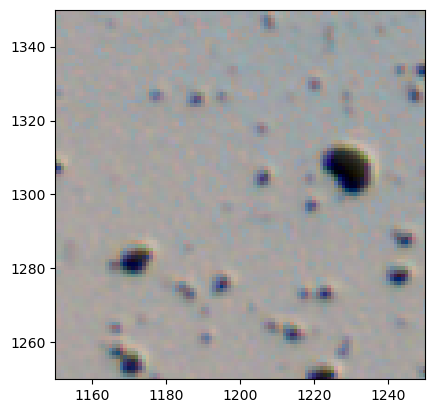

In [7]:
plt.imshow(whole_subs)
plt.xlim(1150,1250)
plt.ylim(1250,1350)

In [8]:
path = '../spectral_libraries/OPTIR/Pilot_Phase_Field_Samples/'
files = os.listdir(path)

In [10]:
for i, f in enumerate(files):
    if f[-5:] != '.ptir':
        files.remove(f)
files

['MEC_02_066_ICB_AlSI_1_054261023_05252023_Run2.ptir',
 'MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2.ptir',
 'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run1.ptir',
 'MEC_02_074_IAO_AlSI_1_04261023_05252023_Run3.ptir',
 'MEC_02_066_ICB_AlSI_1_054261023_05252023_Run3.ptir',
 'MEC_02_068_FHS_AlSI_1_051023_06072023_Run1.ptir',
 'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run2.ptir',
 'MEC_02_066_FHS_AlSI_1_051023_06072023_Run2.ptir',
 'MEC_02_066_FHS_AlSI_1_051023_06072023_Run3.ptir',
 'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run3.ptir',
 'MEC_02_066_ICB_AlSI_1_054261023_05252023_Run1.ptir',
 'MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1.ptir']

In [11]:
files_codes = pd.merge(pd.DataFrame({'file_name':files,
                                     'key':[str(x[11:19]) for x in files],
                                     'run':[str(x[-9:-5]) for x in files]}),
                       pd.DataFrame({'key':['DC_AlSI_','Daycroft', 'FHS_AlSI', 'IAO_AlSI', 'ICB_AlSI'],
                                     'school':['Daycroft', 'Daycroft', 'FHS', 'IAO', 'ICB']
                                     #'school':['Daycroft', 'FHS', 'IAO', 'ICB']
                                     }))

In [12]:
spectra_list = []
for f in files:
    if f == 'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run1.ptir':
        print('error')
        spectra_list.append([])
        continue
    print(f)
    absolute_filename = FileFormat.locate(path + f)
    reader = FileFormat.get_reader(absolute_filename)
    spectra = read_spectra(reader)
    spectra = Orange.data.Table(path + f)
    spectra_list.append(spectra)    
    
coords_list = {f:np.float64(spectra.to_pandas_dfs()[2]) if len(spectra)>0 else [] for f, spectra in zip(files, spectra_list)}

MEC_02_066_ICB_AlSI_1_054261023_05252023_Run2.ptir
MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2.ptir
error
MEC_02_074_IAO_AlSI_1_04261023_05252023_Run3.ptir
MEC_02_066_ICB_AlSI_1_054261023_05252023_Run3.ptir
MEC_02_068_FHS_AlSI_1_051023_06072023_Run1.ptir
MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run2.ptir
MEC_02_066_FHS_AlSI_1_051023_06072023_Run2.ptir
MEC_02_066_FHS_AlSI_1_051023_06072023_Run3.ptir
MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run3.ptir
MEC_02_066_ICB_AlSI_1_054261023_05252023_Run1.ptir
MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1.ptir


In [13]:
coords_list

{'MEC_02_066_ICB_AlSI_1_054261023_05252023_Run2.ptir': array([[2516.35009766, 3905.60009766],
        [2545.5       , 3882.64990234],
        [2518.25      , 3873.44995117],
        [2514.75      , 3874.14990234],
        [2512.        , 3875.69995117],
        [2534.85009766, 3898.19995117],
        [2543.55004883, 3937.        ],
        [2547.94995117, 3935.55004883],
        [2530.75      , 3927.80004883],
        [2559.10009766, 3918.44995117],
        [2540.80004883, 3925.30004883],
        [2543.55004883, 3937.        ],
        [2547.94995117, 3935.55004883],
        [2530.75      , 3927.80004883],
        [2559.10009766, 3918.44995117],
        [2540.80004883, 3925.30004883],
        [2535.19995117, 3958.44995117],
        [2565.14990234, 3964.05004883],
        [2631.60009766, 3972.94995117],
        [2652.30004883, 3975.39990234],
        [2616.69995117, 3991.14990234],
        [2657.94995117, 4010.69995117],
        [2687.35009766, 4019.44995117],
        [2685.55004883, 40

In [16]:
dir_paht = 'Al_Si_1/'
sys.path.append(dir_paht)
sub_dir_paths = os.listdir(dir_paht)
sub_dir_paths.remove('.DS_Store')
image_table = defaultdict(list)
image_list = []
for sdp in sub_dir_paths:
    files_img = os.listdir(dir_paht + sdp)
    images = [cv.imread(os.path.join(dir_paht + sdp, x))
          for x in files_img if x[-3:] == 'tif']
    images = [cv.cvtColor(image, cv.COLOR_BGR2RGB) for image in images]
    print(sdp)
    if sdp[:-7] == 'DC':
        image_table['school'] += ['Daycroft']*3
    else:
        image_table['school'] += [sdp[:-7]]*3
    image_table['run'] += [x[-8:-4] for x in files_img if x[-3:] == 'tif']
    image_table['img_id'] += [x[:-4] for x in files_img if x[-3:] == 'tif']
    image_list += images
image_table = pd.DataFrame(image_table)

FHS_AlSi_1
ICB_AlSi_1
DC_AlSi_1
IAO_AlSi_1


In [17]:
files

['MEC_02_066_ICB_AlSI_1_054261023_05252023_Run2.ptir',
 'MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2.ptir',
 'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run1.ptir',
 'MEC_02_074_IAO_AlSI_1_04261023_05252023_Run3.ptir',
 'MEC_02_066_ICB_AlSI_1_054261023_05252023_Run3.ptir',
 'MEC_02_068_FHS_AlSI_1_051023_06072023_Run1.ptir',
 'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run2.ptir',
 'MEC_02_066_FHS_AlSI_1_051023_06072023_Run2.ptir',
 'MEC_02_066_FHS_AlSI_1_051023_06072023_Run3.ptir',
 'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run3.ptir',
 'MEC_02_066_ICB_AlSI_1_054261023_05252023_Run1.ptir',
 'MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1.ptir']

In [19]:
#[up, left, donw, right] 
coors_ref_list = {files[0]:[4378.38, 1977.16, 3435.57,3234.84],
                  #files[1]:[1874.38,170.11,931.57,1427.79],
                  files[1]:[1652.1,466.65,1153.9,1131.3],
                  files[2]:[-1426.97, 7173.96, 8431.64],
                  files[3]:[3801.38, 3100.16, 2858.57, 4357.84],
                  files[4]:[2978.38, -3125.84, 2035.57, -1868.16],
                  files[5]:[3711.33, 9633.11, 2768.57, 10890.84],
                  files[6]:[5893.73, 5190.26, 4950.92, 6447.94],
                  files[7]:[3503.38, -1861.84, 2560.57, -604.16],
                  files[8]:[-3133.6, -7826.84, -4076.48, -6569.16],
                  files[9]:[1026.38, -11846.84, 83.57, -10589.16],
                  files[10]:[1461.38, -1854.84, 518.57, -597.16],
                  files[11]:[-95.62, -849.84, -1038.43, 407.89]}
len(coors_ref_list)

12

In [20]:
image_table.iloc[:,2]

0     FHS_AlSi_1_Run1
1     FHS_AlSi_1_Run3
2     FHS_AlSi_1_Run2
3     ICB_AlSi_1_Run1
4     ICB_AlSi_1_Run2
5     ICB_AlSi_1_Run3
6        DC_AlSi_Run2
7        DC_AlSi_Run3
8        DC_AlSi_Run1
9     IAO_AlSi_1_Run1
10    IAO_AlSi_1_Run3
11    IAO_AlSi_1_Run2
Name: img_id, dtype: object

In [47]:
pix_mean = np.array(image_list).mean((0,1,2))
pix_adjustment =[1.15*pix_mean/img.mean((0,1)) for img in image_list]
image_adj_list = [np.uint8(image*pix_adjustment[i]) for i, image in enumerate(image_list)]

0 FHS_AlSi_1_Run1
MEC_02_068_FHS_AlSI_1_051023_06072023_Run1.ptir


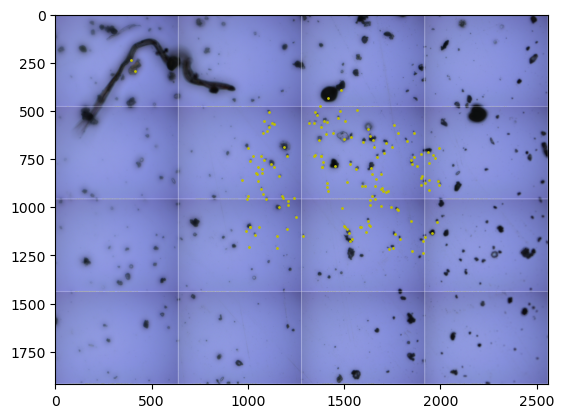

1 FHS_AlSi_1_Run3
MEC_02_066_FHS_AlSI_1_051023_06072023_Run3.ptir


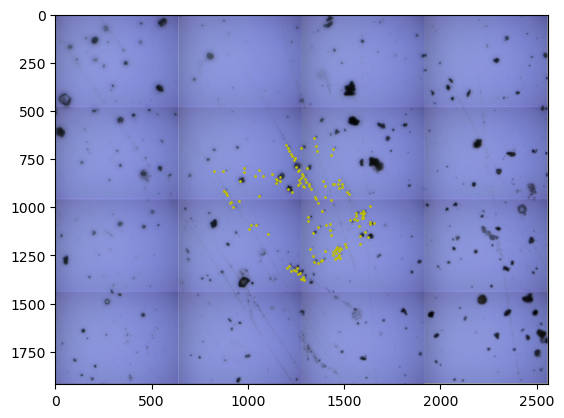

2 FHS_AlSi_1_Run2
MEC_02_066_FHS_AlSI_1_051023_06072023_Run2.ptir


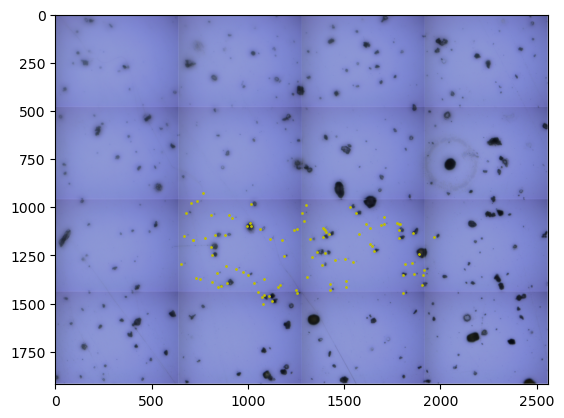

3 ICB_AlSi_1_Run1
MEC_02_066_ICB_AlSI_1_054261023_05252023_Run1.ptir


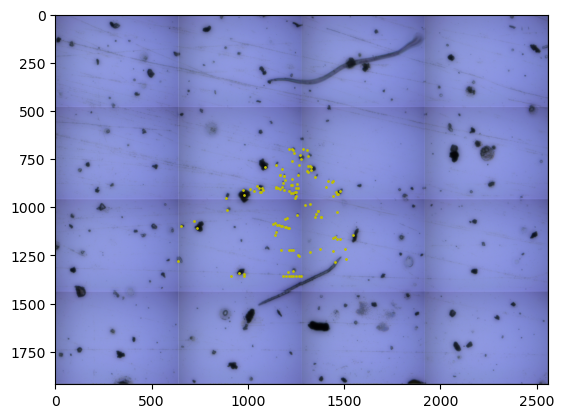

4 ICB_AlSi_1_Run2
MEC_02_066_ICB_AlSI_1_054261023_05252023_Run2.ptir


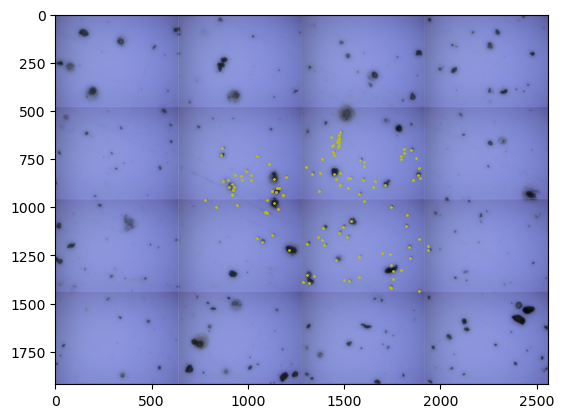

5 ICB_AlSi_1_Run3
MEC_02_066_ICB_AlSI_1_054261023_05252023_Run3.ptir


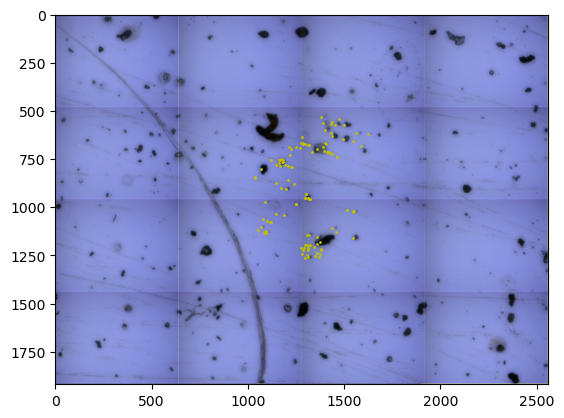

6 DC_AlSi_Run2
MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run2.ptir


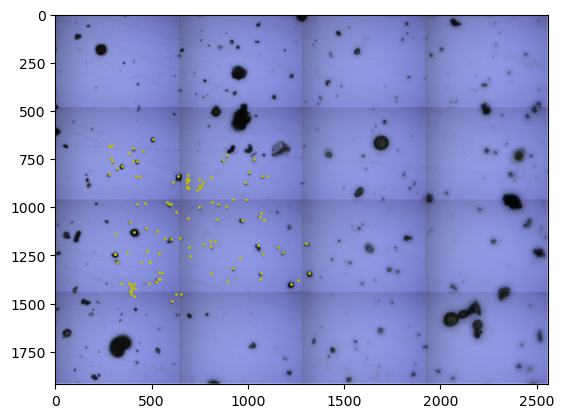

7 DC_AlSi_Run3
MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run3.ptir


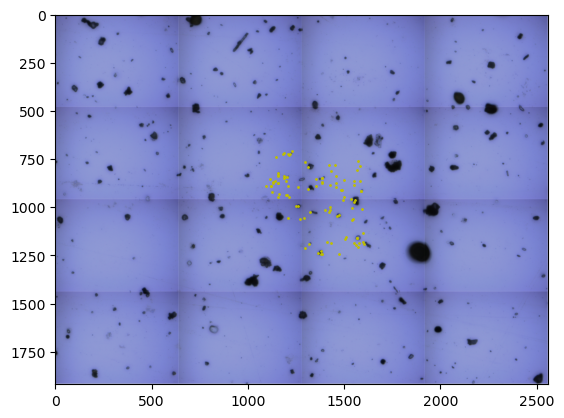

8 DC_AlSi_Run1
MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run1.ptir


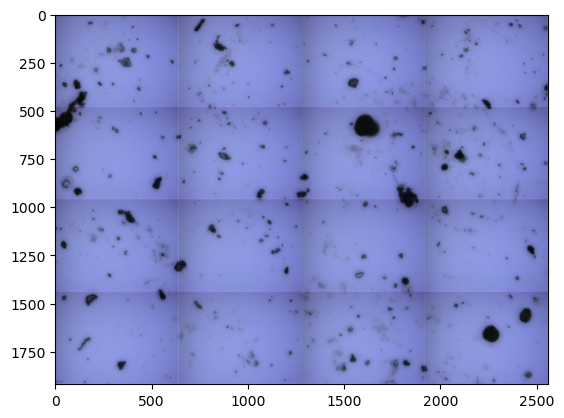

9 IAO_AlSi_1_Run1
MEC_02_074_IAO_AlSI_1_04261023_05252023_Run1.ptir


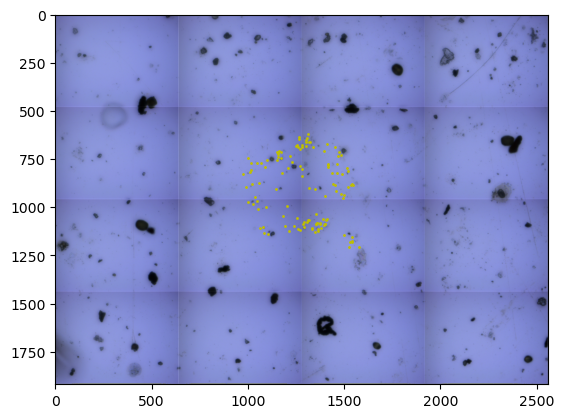

10 IAO_AlSi_1_Run3
MEC_02_074_IAO_AlSI_1_04261023_05252023_Run3.ptir


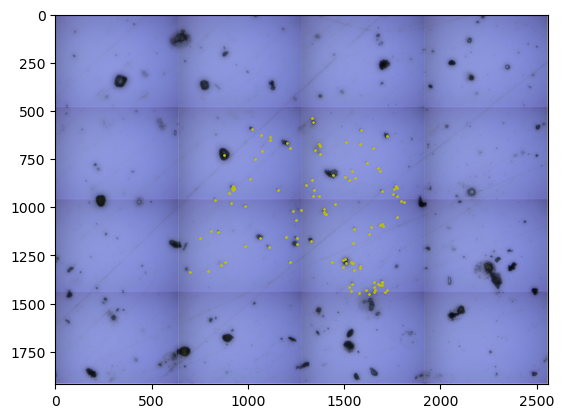

11 IAO_AlSi_1_Run2
MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2.ptir


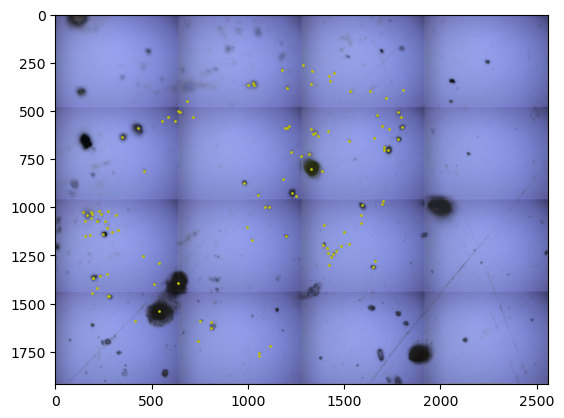

In [22]:
image = image_list[1]
new_coords_list = []
alpha_beta_list = []
for i, image in enumerate(image_list):
    school, run, img_id = (image_table.iloc[i,:])
    print(i, img_id)
    file_id = files_codes.query('school == @school and run == @run')['file_name'].values[0]
    print(file_id)
    #spectr_idx = files_codes.query('school == @school and run == @run').index[0]
    coords = coords_list[file_id]
    coors_ref = coors_ref_list[file_id]
    
    adj_image = np.uint8(image*pix_adjustment[i])
    plt.imshow(adj_image)
    
    if len(coords) == 0:
        new_coords_list.append(np.array(0))
        plt.show()
        continue
    #plt.scatter(coords_t[::-,0], coords_t[::-1,1], c='y')
    #plt.scatter(10240* (coords[:,0]-9633.11) /(10890.84 - 9633.11), 7680* (coords[:,1]-2768.57) /(3711.33 - 2768.57), c='y',s=.5)


    alpha = image.shape[1]/(coors_ref[3] - coors_ref[1])
    #alpha = 2560/(7826.84 - 6569.16)
    a = 0#115

    beta = image.shape[0]/(coors_ref[0] - coors_ref[2])
    #beta = 1920/(4076.48 - 3133.6)
    b = 0#110
    
    alpha_beta_list.append((alpha, beta))
    
    new_coord_x = alpha*(coords[:,0] - coors_ref[1]) + a
    new_coord_y = -beta*(coords[:,1]-coors_ref[0]) + b

    n_coords = new_coord_x.shape[0]

    #new_coord_x_aug = (new_coord_x.reshape(n_coords,1) + np.arange(-10,10).reshape(1,20)).reshape(-1,1)
    #new_coord_y_aug = (new_coord_y.reshape(n_coords,1) + np.arange(-10,10).reshape(1,20)).reshape(-1,1)

    plt.scatter(
         new_coord_x,
        new_coord_y,
        c='y', s=1)
    plt.show()
    
    new_coords_list.append((new_coord_y,new_coord_x))

    #plt.scatter(
    #     new_coord_x[hits_index],
    #    new_coord_y[hits_index],
    #    c='r', s=5)

    #plt.scatter(
    #     new_coord_x[bg_index],
    #    new_coord_y[bg_index],
    #    c='w', s=1)



In [ ]:
MEC_02_074_IAO_AlSI_1_Run2.tif

In [48]:
i = -1
coords = np.array(new_coords_list[i]).T
image = image_adj_list[i]
sizes_distr, FF, solidities, mask, mask_keep = particle_filter(image, coords, alpha, beta, thr_l=10, thr_h=120, t=50)
sizes_distr.shape

(34,)

In [44]:
coords.shape

(117, 2)

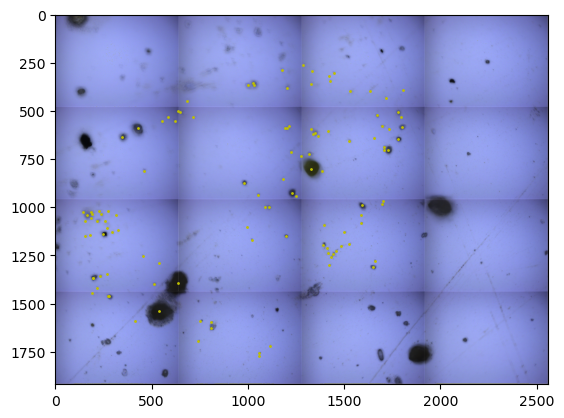

In [49]:
plt.imshow(image)
plt.scatter(
     coords[:,1],
    coords[:,0],
     c='y', s=1)
#plt.xlim(1150,1400)
#plt.ylim(1250,1500)

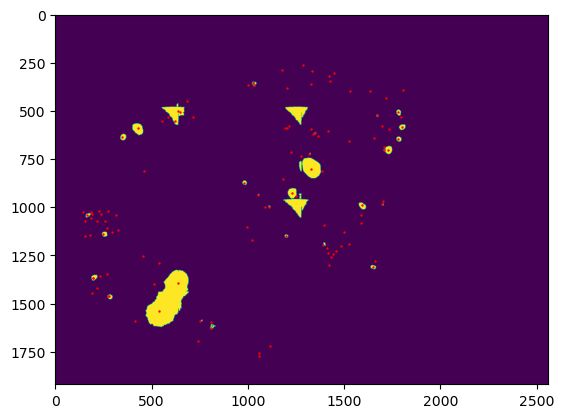

In [50]:
plt.imshow(mask_keep)
plt.scatter(
     coords[:,1],
    coords[:,0],
    c='r', s=.5)

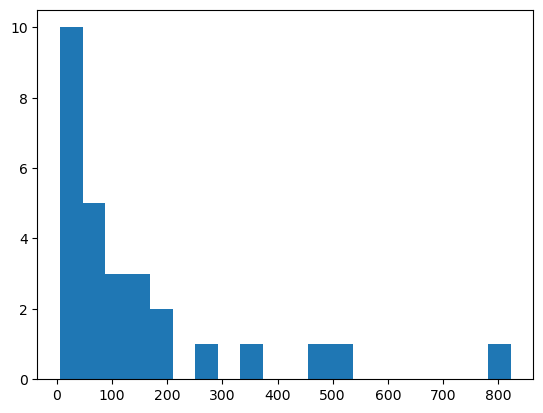

In [32]:
_ = plt.hist(sizes_distr[sizes_distr<sizes_distr.max()],bins=20)

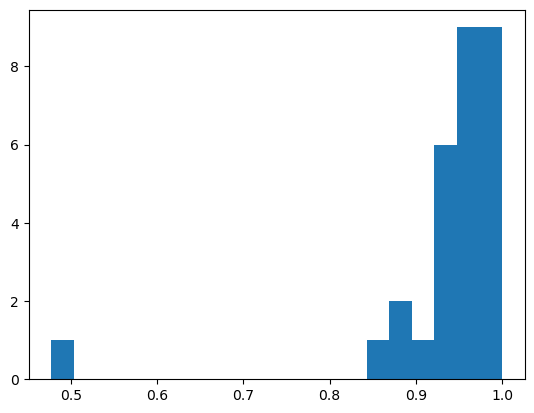

In [34]:
_ = plt.hist(solidities,bins=20)

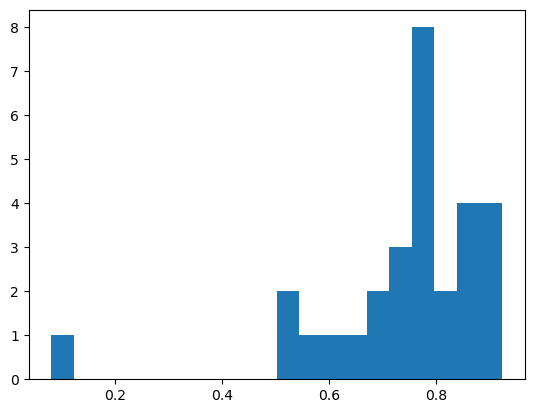

In [37]:
_ = plt.hist(FF,bins=20)

(1250.0, 1500.0)

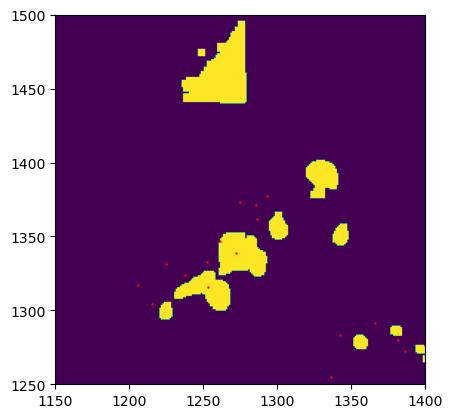

In [65]:
pix_mean = np.array(image_list).mean((0,1,2))
pix_adjustment =[1.1*pix_mean/img.mean((0,1)) for img in image_list]
image_adj_list = [np.uint8(image*pix_adjustment[i]) for i, image in enumerate(image_list)]
i = 1
coords = np.array(new_coords_list[i]).T
image = image_adj_list[i]

mask = particle_dection(image, thr_l=0, thr_h=120)
plt.imshow(mask)
plt.scatter(
     coords[:,1],
    coords[:,0],
    c='r', s=.5)
plt.xlim(1150,1400)
plt.ylim(1250,1500)

(1250.0, 1500.0)

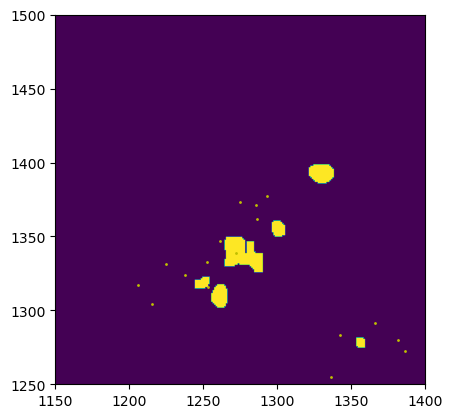

In [48]:
plt.imshow(mask_keep)
plt.scatter(
     coords[:,1],
    coords[:,0],
     c='y', s=1)
plt.xlim(1150,1400)
plt.ylim(1250,1500)

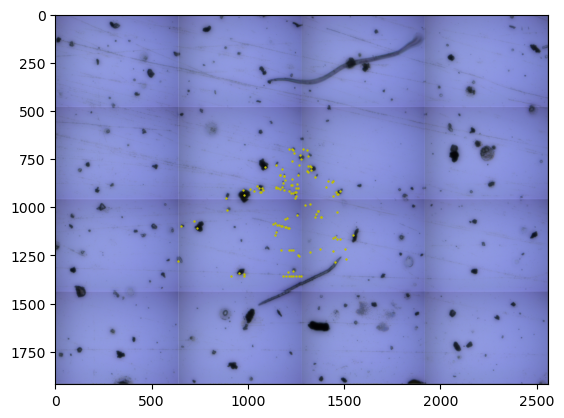

In [33]:
plt.imshow(image)
plt.scatter(
     coords[:,1],
    coords[:,0],
    c='y', s=.5)

In [27]:
sizes_distr.max()

2973.309160534668

In [34]:
coords.shape

(127, 2)

In [29]:
pd.DataFrame({'size':sizes_distr,'FF':FF})

,size,FF
0,56.209415,0.672168
1,46.077245,0.765362
2,45.353519,0.841039
3,155.359927,0.793328
4,512.157026,0.771141
5,37.151287,0.715688
6,200.472204,0.789615
7,22.676760,0.862848
8,23.400486,0.844140
9,5.789811,0.835437


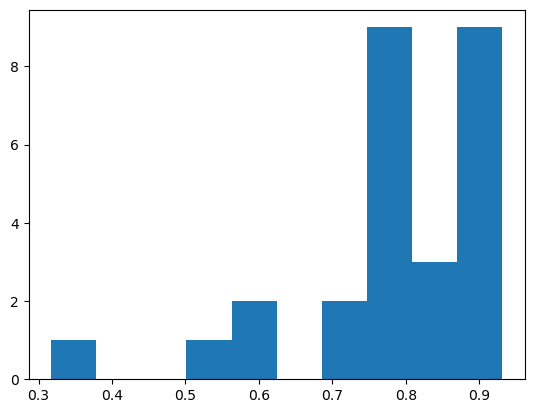

In [23]:
_ = plt.hist(FF)

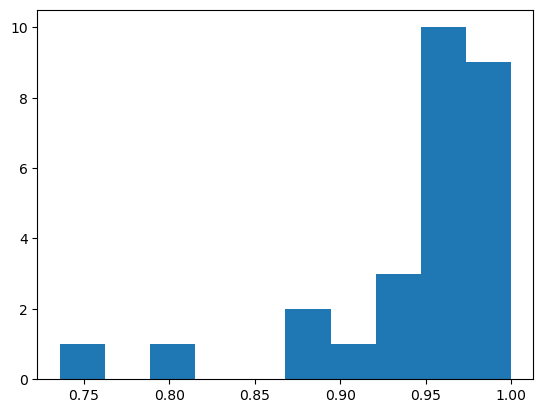

In [24]:
_ = plt.hist(solidities)

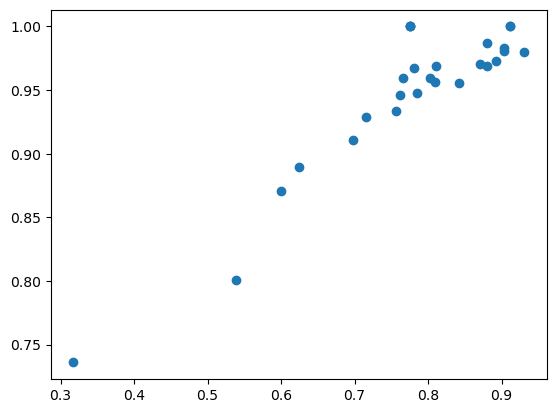

In [26]:
plt.scatter(FF, solidities)

In [127]:
#table_results = pd.read_csv('../spectral_libraries/Pilot_Phase_Field_Samples_results/table_results.csv')
#hits_index = table_results.query('school == "FHS" and run == "Run1"')['sample_id'].to_numpy()
#MEC_02_066_FHS_AlSI_1_051023_06072023_Run2

In [134]:
#background = pd.read_csv('../spectral_libraries/OPTIR/Pilot_Phase_Field_Samples/data_background.csv')
#bg_index = background.query('school == "FHS" and run == "Run1"')['sample_id'].to_numpy()

In [220]:
#grayscale = cv.cvtColor(np.uint8(image_list[1]*pix_adjustment[1]), cv.COLOR_BGR2GRAY)
#plt.imshow(grayscale)

In [219]:
#plt.hist(grayscale.flatten())

In [215]:
def particle_dection(image):

    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    
    low = np.array([0])
    high = np.array([np.int64(np.quantile(gray, .025))])
    
    #ret, thresh = cv.threshold(gray,0,255, 9)#,cv.THRESH_BINARY_INV+cv.THRESH_OTSU)
    thresh = cv.inRange(gray, low, high)

    # noise removal
    kernel = np.ones((3,3),np.uint8)
    opening = cv.morphologyEx(thresh,cv.MORPH_OPEN,kernel, iterations = 2)
    # sure background area
    sure_bg = cv.dilate(opening,kernel,iterations=3)
    # Finding sure foreground area
    dist_transform = cv.distanceTransform(opening,cv.DIST_L2,5)
    ret, sure_fg = cv.threshold(dist_transform,0.7*dist_transform.max(),255,0)
    # Finding unknown region
    sure_fg = np.uint8(sure_fg)
    unknown = cv.subtract(sure_bg,sure_fg)

    dist_transform = cv.distanceTransform(opening,cv.DIST_L2,5)
    ret, sure_fg = cv.threshold(dist_transform,0.01*dist_transform.max(),255,0)

    mask = (sure_fg==255)
    return mask

In [52]:
mask = particle_dection(image_adj_list[1])

In [55]:
#new_coords_list[1][1]
np.array(new_coords_list[1]).T

array([[ 920.108504  , 1227.99352777],
       [ 903.91990497, 1207.84134279],
       [ 872.56086405, 1145.8611491 ],
       [ 862.98978926, 1165.91096304],
       [ 860.13914814, 1150.44101043],
       [ 851.99389106, 1146.57377075],
       [ 826.94712609, 1126.93045926],
       [ 844.96870625, 1165.5034667 ],
       [ 837.94352144, 1035.43560365],
       [ 835.19429832, 1077.87585077],
       [ 806.99114681, 1060.67552955],
       [ 817.17271816,  979.35714967],
       [ 794.16276461,  982.41039056],
       [ 864.41560697,  957.98446346],
       [ 810.55469678,  825.57598117],
       [ 813.60916819,  873.10496311],
       [ 979.05970272,  904.85886712],
       [ 972.34026334,  914.83258858],
       [ 935.58469132,  891.22066026],
       [ 928.25376108,  886.23330259],
       [ 913.89764604,  874.52921252],
       [ 914.10147633,  874.63158355],
       [1000.13575428,  925.51893168],
       [ 968.98004651,  955.13497074],
       [ 943.7299484 , 1060.57415241],
       [1113.35502662, 10

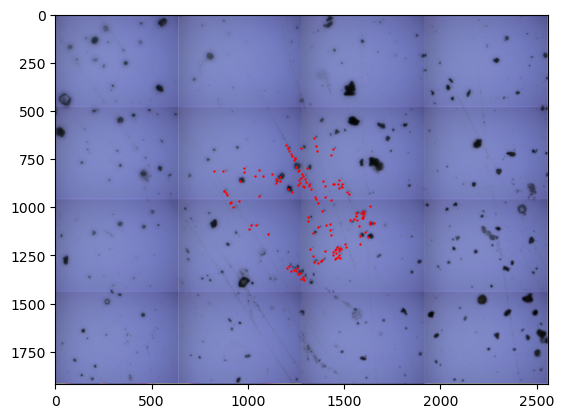

In [53]:
plt.imshow(image_adj_list[1])
plt.scatter(
     new_coords_list[1][1],
    new_coords_list[1][0],
    c='r', s=.5)


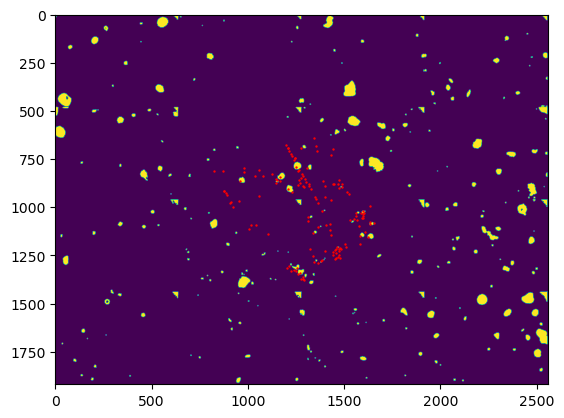

In [252]:
plt.imshow(mask)
plt.scatter(
     new_coords_list[1][1],
    new_coords_list[1][0],
    c='r', s=.5)


In [420]:
ret, labels = cv.connectedComponents(((mask.astype('uint8')) * 255))

In [421]:
coords_labels_list = [np.array(np.where(labels == i)).T for i in range(1,ret)]

In [422]:
new_coords = np.array(new_coords_list[1]).T

In [423]:
distances_part = np.array([pairwise_distances(c, new_coords).min() for c in coords_labels_list])

In [424]:
keep_idx = np.where(distances_part < 60)[0]+1
keep_idx

array([ 85,  93,  96,  98, 105, 108, 109, 113, 114, 122, 133, 135, 136,
       139, 142, 144, 147, 150, 154, 155, 163, 173, 176, 177, 180, 182,
       183, 187, 193, 195, 202])

In [425]:
true_areas = np.array([(labels==i).sum() for i in keep_idx])

In [426]:
bbox_areas = np.array([np.prod(np.array(np.where(labels==i)).max(1) - np.array(np.where(labels==i)).min(1) + 1) for i in keep_idx])
#bbox_areas = np.array([np.prod(c.max(0) - c.min(0) + 1) for c in coords_labels_list])

In [427]:
solidities = true_areas / bbox_areas

In [429]:
sizes_distr = true_areas / (alpha*beta)
sizes_distr

array([ 56.20941456,  35.46259202, 289.24930495,  94.80815417,
       235.21106949, 175.86550735,  23.88297013, 235.21106949,
        12.54459037, 124.72217736,  10.13216915,  52.59078272,
        27.50160197,  30.15526532,  24.12421226,  65.13537309,
         9.6496849 ,  40.52867659,  86.605922  , 162.83843273,
        11.33837976,   6.03105306,   7.23726368,  17.85191707,
        10.85589552,  20.50558042, 128.09956708, 167.18079093,
        25.81290711,  39.80495022,  77.92120559])

In [431]:
mask_keep_list = [labels == i for i in keep_idx]

In [432]:
mask_keep = mask_keep_list[0] 
for m in mask_keep_list:
    mask_keep = mask_keep + m
mask_keep

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

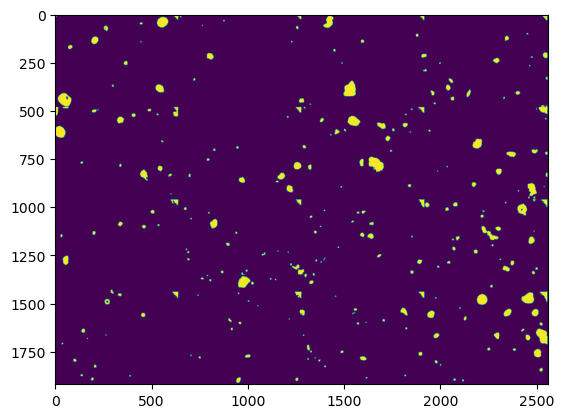

In [433]:
plt.imshow(mask)

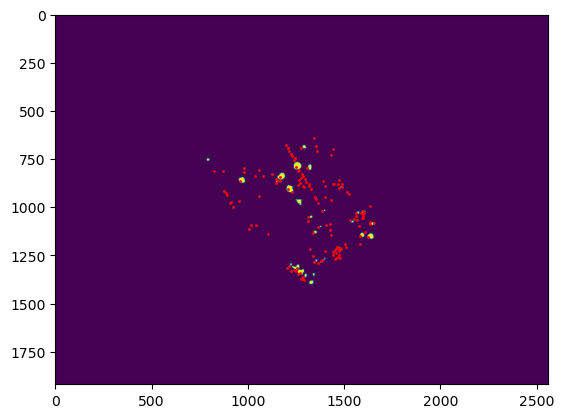

In [434]:
plt.imshow(mask_keep)
plt.scatter(new_coords[:,1], new_coords[:,0], s=1, c='r')

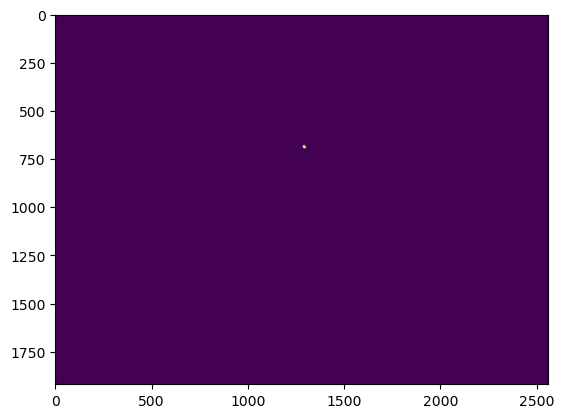

In [435]:
plt.imshow(labels==85)

In [494]:
perimeters = []
true_areas_ = []
chull_areas = []
for i in keep_idx:
    mask_1 = np.uint8(labels==i)
    contours,hierarchy = cv.findContours(mask_1, cv.RETR_TREE,cv.CHAIN_APPROX_SIMPLE)
    cnt = contours[0]
    hull = cv.convexHull(cnt)
    perimeter = cv.arcLength(cnt, True)
    area = cv.contourArea(cnt)
    ch_area = cv.contourArea(hull)
    #mask_1_ = mask_1.copy()
    #cv.drawContours(mask_1_, [cnt], -1, (0,255,255), 1)
    #perimeters.append((mask_1.sum() - mask_1_.sum()))
    perimeters.append(perimeter)
    true_areas_.append(area)
    chull_areas.append(ch_area)
perimeters = np.int64(perimeters)
true_areas_ = np.int64(true_areas_)
chull_areas = np.int64(chull_areas)

In [488]:
cv.contourArea(cnt)

292.5

In [485]:
hull = cv.convexHull(cnt)

In [487]:
cv.contourArea(hull)

301.5

In [495]:
chull_areas

array([ 217,  129, 1168,  371,  972,  715,   83,  973,   40,  524,   30,
        199,   99,  109,   85,  250,   29,  150,  340,  658,   35,   16,
         20,   59,   34,   71,  647,  715,   89,  154,  301])

In [496]:
true_areas_

array([ 207,  126, 1142,  358,  921,  683,   80,  920,   40,  461,   30,
        192,   96,  106,   82,  241,   29,  147,  328,  632,   35,   16,
         20,   59,   33,   69,  479,  640,   88,  142,  292])

In [497]:
FF = 4*np.pi*true_areas_ / (perimeters ** 2)
solidities = true_areas_ / chull_areas

In [481]:
(true_areas - true_areas_)

array([26, 21, 57, 35, 54, 46, 19, 55, 12, 56, 12, 26, 18, 19, 18, 29, 11,
       21, 31, 43, 12,  9, 10, 15, 12, 16, 52, 53, 19, 23, 31])

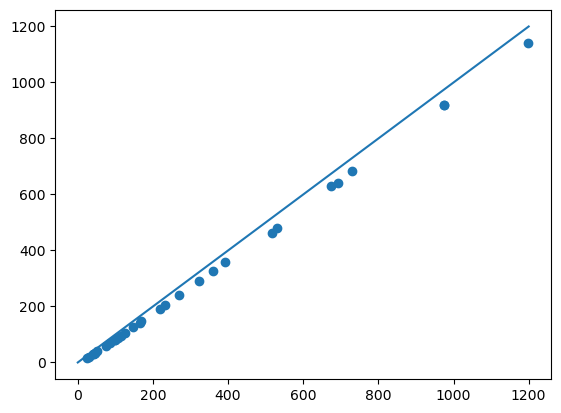

In [483]:
plt.scatter(true_areas, true_areas_)
plt.plot(np.linspace(0,1200,100), np.linspace(0,1200,100))

In [412]:
#area = cv.contourArea(cnt)
#perimeter = cv.arcLength(cnt, True)
#perimeter = round(perimeter, 4)
#area, perimeter

In [416]:
#mask_1_ = mask_1.copy()
#mask_1_1 = cv.drawContours(mask_1_, [cnt], -1, (0,255,255), 1)

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

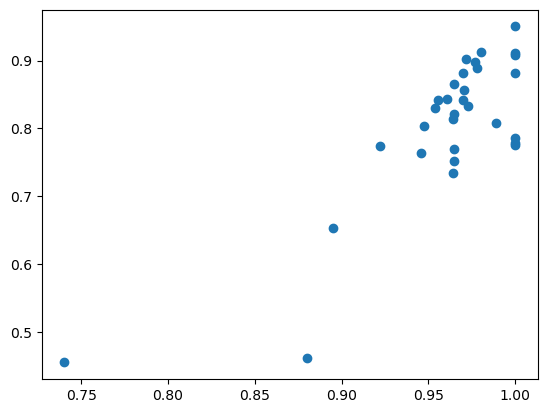

In [498]:
plt.scatter(solidities,FF)

(array([2., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 5., 2., 4., 5., 2.,
        4., 4., 1.]),
 array([0.45514492, 0.47989758, 0.50465024, 0.5294029 , 0.55415556,
        0.57890823, 0.60366089, 0.62841355, 0.65316621, 0.67791887,
        0.70267154, 0.7274242 , 0.75217686, 0.77692952, 0.80168218,
        0.82643485, 0.85118751, 0.87594017, 0.90069283, 0.92544549,
        0.95019816]),
 <BarContainer object of 20 artists>)

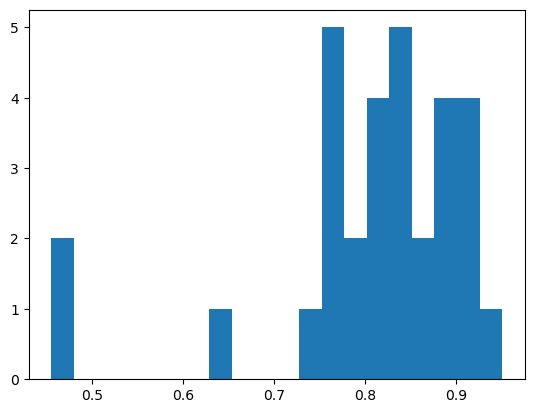

In [499]:
plt.hist(FF, 20)

(array([ 1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,  0.,
         1.,  0.,  2.,  3., 11.,  3.,  8.]),
 array([0.74034003, 0.75332303, 0.76630603, 0.77928903, 0.79227202,
        0.80525502, 0.81823802, 0.83122102, 0.84420402, 0.85718702,
        0.87017002, 0.88315301, 0.89613601, 0.90911901, 0.92210201,
        0.93508501, 0.94806801, 0.961051  , 0.974034  , 0.987017  ,
        1.        ]),
 <BarContainer object of 20 artists>)

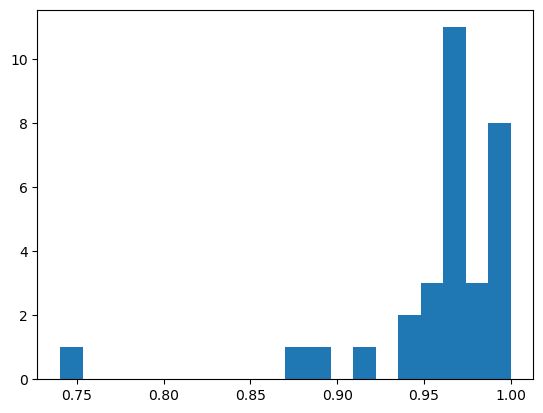

In [500]:
plt.hist(solidities, 20)

(array([8., 6., 3., 2., 1., 2., 1., 0., 2., 0., 0., 3., 0., 0., 0., 0., 2.,
        0., 0., 1.]),
 array([  6.03105306,  20.19196566,  34.35287825,  48.51379085,
         62.67470344,  76.83561603,  90.99652863, 105.15744122,
        119.31835382, 133.47926641, 147.64017901, 161.8010916 ,
        175.96200419, 190.12291679, 204.28382938, 218.44474198,
        232.60565457, 246.76656717, 260.92747976, 275.08839235,
        289.24930495]),
 <BarContainer object of 20 artists>)

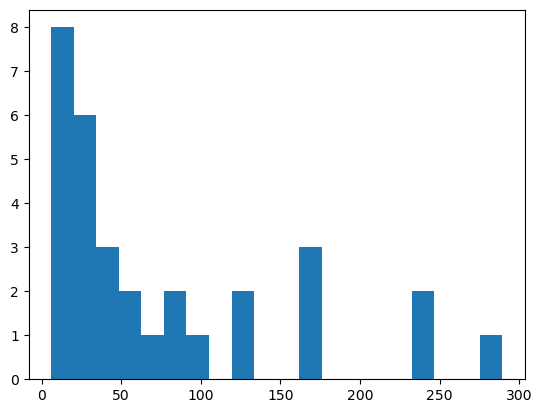

In [382]:
plt.hist(sizes_distr, 20)